## RANDOM FOREST IMPROVEMENT
**Phương pháp:** Feature Importance-Based Feature Selection (Top 35).

**Phạm vi Notebook:** lựa chọn đặc trưng từ Random Forest baseline đã học trên Train, huấn luyện lại RF với 120 cây, xem thông số quá trình dựng cây, lưu mô hình, kiểm tra nạp lại và ghi nhật ký.

In [4]:
from pathlib import Path
from datetime import datetime, timezone
import csv, json, time, hashlib, platform
import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"
REPORTS = ROOT / "reports" / "07A_random_forest_improvement"
TABLES = REPORTS / "tables"
FIGURES = REPORTS / "figures"
RESULTS = ROOT / "results"
LOG = ROOT / "Nhat_ky_thuc_nghiem_RF.csv"
for directory in (DATA, MODELS / "improved", TABLES, FIGURES, RESULTS):
    directory.mkdir(parents=True, exist_ok=True)

LOG_FIELDS = [
    "experiment_id", "timestamp_utc", "model", "improvement_method", "stage",
    "step", "total_steps", "split_scheme", "train_rows", "validation_rows",
    "test_rows_reserved", "feature_count", "parameters_json", "seed",
    "epoch", "train_loss", "validation_loss", "trees_inspected", "mean_tree_depth",
    "mean_tree_nodes", "elapsed_seconds", "status", "artifact_path", "notes"
]
def log_event(experiment_id, model, method, stage, step="", total_steps="", feature_count="",
              parameters=None, epoch="", train_loss="", validation_loss="", trees_inspected="",
              mean_tree_depth="", mean_tree_nodes="", elapsed_seconds="", status="OK",
              artifact_path="", notes=""):
    row = {k: "" for k in LOG_FIELDS}
    row.update(experiment_id=experiment_id, timestamp_utc=datetime.now(timezone.utc).isoformat(),
               model=model, improvement_method=method, stage=stage, step=step,
               total_steps=total_steps, split_scheme="70/15/15 stratified; seed=42",
               train_rows=82536, validation_rows=17686, test_rows_reserved=17687,
               feature_count=feature_count,
               parameters_json=json.dumps(parameters or {}, ensure_ascii=False, sort_keys=True),
               seed=42, epoch=epoch, train_loss=train_loss, validation_loss=validation_loss,
               trees_inspected=trees_inspected, mean_tree_depth=mean_tree_depth,
               mean_tree_nodes=mean_tree_nodes, elapsed_seconds=elapsed_seconds,
               status=status, artifact_path=artifact_path, notes=notes)
    create_header = not LOG.exists()
    with LOG.open("a", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=LOG_FIELDS)
        if create_header:
            writer.writeheader()
        writer.writerow(row)

def sha256(path):
    h = hashlib.sha256()
    with open(path,"rb") as f:
        for block in iter(lambda:f.read(1024*1024),b""):
            h.update(block)
    return h.hexdigest()

print("Thư mục dự án:", ROOT)
print("scikit-learn:", sklearn.__version__, "| Python:", platform.python_version())


Thư mục dự án: C:\homework\Machine Learning\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\ĐỒ ÁN CUỐI KỲ NHÓM 4
scikit-learn: 1.7.2 | Python: 3.13.9


### 1.Kiểm tra input

In [5]:
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import InconsistentVersionWarning

rf_train = pd.read_csv(DATA / "rf_train.csv")
feature_names = rf_train.columns.drop("Attack_type").tolist()
X_train = rf_train[feature_names].to_numpy(dtype=np.float32)
y_train = rf_train["Attack_type"].to_numpy(dtype=np.int32)
assert X_train.shape == (82536, 92)
assert np.isfinite(X_train).all()
assert sorted(np.unique(y_train).tolist()) == list(range(12))
print("Train:",X_train.shape,"| 12 nhãn:",len(np.unique(y_train)))

Train: (82536, 92) | 12 nhãn: 12


### 2. Xếp hạng đặc trưng bằng RF baseline trên Train
Chỉ lấy feature_importances từ RF baseline gốc đã được fit bằng tập Train.

In [6]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", InconsistentVersionWarning)
    rf_baseline = joblib.load(MODELS / "rf_baseline.joblib")
assert rf_baseline.n_features_in_ == len(feature_names)
importance = pd.DataFrame({"feature":feature_names,"importance":rf_baseline.feature_importances_})
importance = importance.sort_values("importance", ascending=False, kind="stable").reset_index(drop=True)
importance.insert(0,"rank",np.arange(1,len(importance)+1))
importance.to_csv(TABLES / "07A_rf_feature_importances_train.csv", index=False, encoding="utf-8-sig")
print(importance.head(15).to_string(index=False))

 rank                    feature  importance
    1  num__fwd_last_window_size    0.042843
    2             num__id.resp_p    0.037491
    3    num__fwd_URG_flag_count    0.036760
    4    num__fwd_PSH_flag_count    0.035184
    5   num__fwd_header_size_min    0.034099
    6   num__flow_FIN_flag_count    0.030643
    7  num__fwd_pkts_payload.avg    0.029548
    8          num__flow_iat.min    0.028558
    9   num__fwd_header_size_max    0.028396
   10      num__bwd_pkts_per_sec    0.024807
   11 num__flow_pkts_payload.avg    0.023913
   12  num__fwd_pkts_payload.max    0.023834
   13 num__flow_pkts_payload.tot    0.023718
   14          cat__service_mqtt    0.023444
   15            num__active.min    0.022066


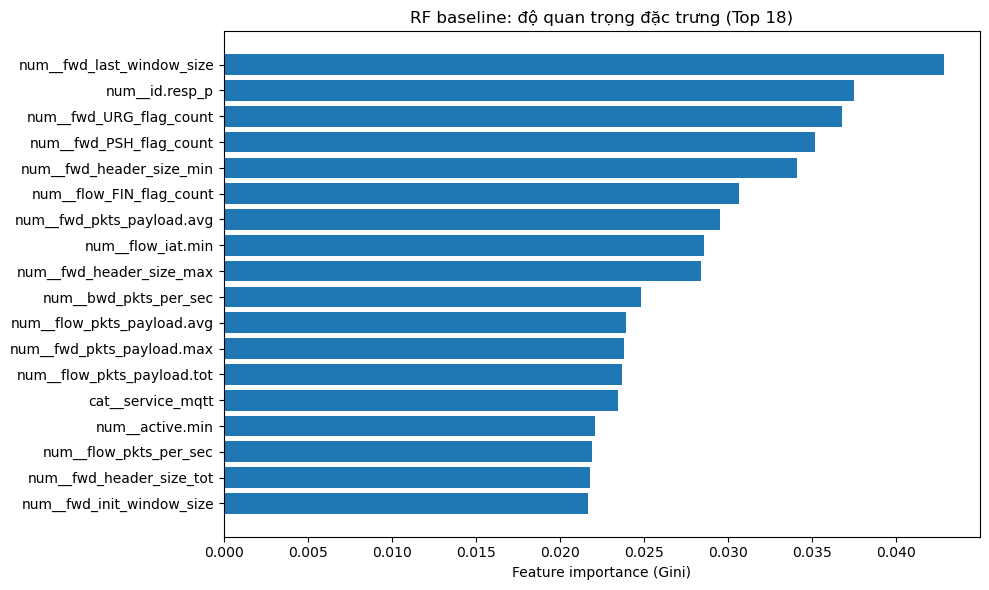

In [7]:
fig, ax = plt.subplots(figsize=(10,6))
top_plot=importance.head(18).iloc[::-1]
ax.barh(top_plot["feature"],top_plot["importance"])
ax.set_title("RF baseline: độ quan trọng đặc trưng (Top 18)")
ax.set_xlabel("Feature importance (Gini)")
fig.tight_layout()
fig.savefig(FIGURES / "07A_rf_feature_importance_top18.png", dpi=160)
plt.show()

### 3. Thiết kế Random Forest cải tiến
- Chọn 35/92 đặc trưng theo importance của RF baseline, bảo toàn thứ tự cột của dữ liệu CSV.
- Giữ cấu hình thuật toán chính: **120 cây, Gini, Bootstrap, max_features='sqrt', class_weight='balanced_subsample', random_state=42**.

In [8]:
TOP_K=35
ranked_feature_indices = [feature_names.index(name) for name in importance.head(TOP_K)["feature"]]
selected_indices=np.sort(np.array(ranked_feature_indices))
selected_features=[feature_names[i] for i in selected_indices]
selected_table=importance.set_index("feature").loc[selected_features].reset_index()
selected_table.to_csv(TABLES / "07A_rf_selected_35_features.csv", index=False, encoding="utf-8-sig")
X_selected=X_train[:, selected_indices]
rf_config=dict(n_estimators=120,criterion="gini",bootstrap=True,max_features="sqrt",
               min_samples_leaf=1,class_weight="balanced_subsample",random_state=42,
               n_jobs=4,warm_start=False,verbose=0)
rf_improved=RandomForestClassifier(**rf_config)
rf_id="B7_RF_TOP35_RUN"
log_event(rf_id,"Random Forest","RF Feature Selection Top 35","START",feature_count=TOP_K,
          parameters=rf_config,notes="RF importance từ baseline fit trên Train; không dùng Validation/Test")
print("Số đặc trưng được giữ:",len(selected_features))
print("Thiết kế:",rf_config)
print("5 đặc trưng đầu tiên:",selected_features[:5])

Số đặc trưng được giữ: 35
Thiết kế: {'n_estimators': 120, 'criterion': 'gini', 'bootstrap': True, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'class_weight': 'balanced_subsample', 'random_state': 42, 'n_jobs': 4, 'warm_start': False, 'verbose': 0}
5 đặc trưng đầu tiên: ['num__id.orig_p', 'num__id.resp_p', 'num__flow_duration', 'num__fwd_pkts_per_sec', 'num__bwd_pkts_per_sec']


### 4. Huấn luyện 120 cây

In [9]:
start=time.perf_counter()
rf_improved.fit(X_selected,y_train)
rf_fit_seconds=time.perf_counter()-start
assert len(rf_improved.estimators_) == 120
assert rf_improved.n_features_in_ == TOP_K
print(f"Đã fit đủ {len(rf_improved.estimators_)} cây trong {rf_fit_seconds:.3f} giây")
log_event(rf_id,"Random Forest","RF Feature Selection Top 35","TRAIN_FINISHED",step=120,
          total_steps=120,feature_count=TOP_K,parameters=rf_config,
          elapsed_seconds=round(rf_fit_seconds,3),notes="Fit 1 lần trên Train, đủ 120 cây")

Đã fit đủ 120 cây trong 12.652 giây


In [10]:
tree_stats=pd.DataFrame([{"tree_number":i+1,"max_depth":int(tree.tree_.max_depth),
                              "node_count":int(tree.tree_.node_count),
                              "n_leaves":int(tree.tree_.n_leaves)}
                             for i,tree in enumerate(rf_improved.estimators_)])
tree_stats.to_csv(TABLES / "07A_rf_tree_structure_120.csv",index=False,encoding="utf-8-sig")
for end in range(20,121,20):
    s=tree_stats.iloc[:end]
    log_event(rf_id,"Random Forest","RF Feature Selection Top 35","TREE_STRUCTURE_SNAPSHOT",
              step=end,total_steps=120,feature_count=TOP_K,parameters=rf_config,
              trees_inspected=end,mean_tree_depth=round(s.max_depth.mean(),3),
              mean_tree_nodes=round(s.node_count.mean(),3),
              notes="Thống kê cấu trúc sau khi đã fit đủ 120 cây")
    print(f"{end:3}/120 cây | độ sâu TB (tích lũy) = {s.max_depth.mean():.2f} | số nút TB = {s.node_count.mean():.1f}")
print("Độ sâu: min",tree_stats.max_depth.min(),"max",tree_stats.max_depth.max())

 20/120 cây | độ sâu TB (tích lũy) = 22.05 | số nút TB = 607.6
 40/120 cây | độ sâu TB (tích lũy) = 21.98 | số nút TB = 594.1
 60/120 cây | độ sâu TB (tích lũy) = 21.92 | số nút TB = 591.3
 80/120 cây | độ sâu TB (tích lũy) = 21.86 | số nút TB = 588.0
100/120 cây | độ sâu TB (tích lũy) = 21.85 | số nút TB = 587.8
120/120 cây | độ sâu TB (tích lũy) = 21.92 | số nút TB = 589.6
Độ sâu: min 17 max 28


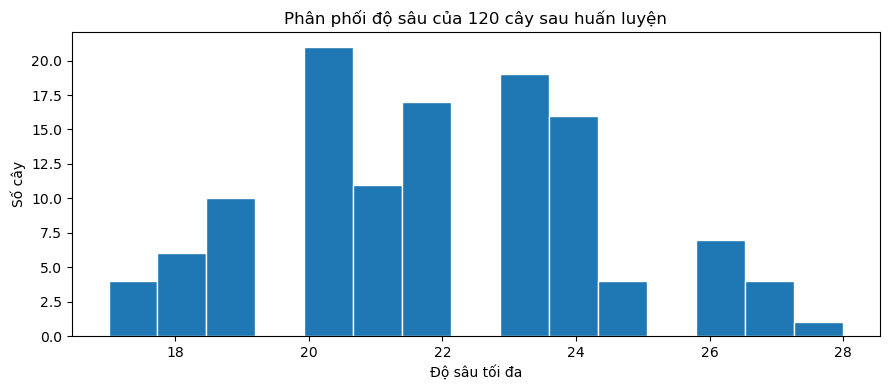

In [11]:
fig,ax=plt.subplots(figsize=(9,4))
ax.hist(tree_stats["max_depth"], bins=15, edgecolor="white")
ax.set(title="Phân phối độ sâu của 120 cây sau huấn luyện",xlabel="Độ sâu tối đa",ylabel="Số cây")
fig.tight_layout()
fig.savefig(FIGURES / "07A_rf_tree_depth_hist.png",dpi=160)
plt.show()

### 5. Lưu và nạp lại mô hình cải tiến
File `.joblib` là estimator đã huấn luyện; `selected_features.csv` giữ tên và thứ tự 35 cột đầu vào cần sử dụng.

In [12]:
rf_model_path=MODELS / "improved" / "rf_feature_selection_top35.joblib"
joblib.dump(rf_improved,rf_model_path,compress=3)
rf_loaded=joblib.load(rf_model_path)
assert np.array_equal(rf_loaded.predict(X_selected[:64]),rf_improved.predict(X_selected[:64]))
rf_meta={"experiment_id":rf_id,"method":"RF feature importance top35","train_rows":len(y_train),
         "input_features":92,"selected_features":selected_features,"n_trees":len(rf_improved.estimators_),
         "fit_seconds":round(rf_fit_seconds,3),"model_sha256":sha256(rf_model_path),
         "scikit_learn_version":sklearn.__version__,"test_untouched":True}
(RESULTS / "07A_rf_training_summary.json").write_text(json.dumps(rf_meta,ensure_ascii=False,indent=2),encoding="utf-8")
log_event(rf_id,"Random Forest","RF Feature Selection Top 35","MODEL_SAVED",
          feature_count=TOP_K,parameters=rf_config,elapsed_seconds=round(rf_fit_seconds,3),
          artifact_path=str(rf_model_path.relative_to(ROOT)),
          notes="Đã nạp lại và xác nhận dự đoán trên 64 mẫu Train khớp với mô hình trước lưu")
print("Đã lưu:",rf_model_path.relative_to(ROOT))
print("SHA256:",rf_meta["model_sha256"])
print("Kiểm tra nạp lại: PASS")

Đã lưu: models\improved\rf_feature_selection_top35.joblib
SHA256: 80a3e9370945f268a7223eaefebd82d1a2695aab8059c5419b78c0cbdbd9c562
Kiểm tra nạp lại: PASS


### 6. Kết luận bước huấn luyện RF cải tiến
Đã xây dựng mô hình RF dùng 35 đặc trưng xếp hạng bằng RF baseline, fit 120 cây trên 82.536 mẫu Train, lưu trọng số và bảng tên cột.